# 02. Product Funnel Analysis — Utility Payments A/B Test

## Цель исследования

Изучить, как пользователи проходят сценарий оплаты ЖКХ в контрольной группе A и тестовой группе B, определить этапы с наибольшими потерями и оценить, где наблюдается самое заметное различие между вариантами формы.

**Основной объект анализа — пользователь**, поскольку экспериментальная группа назначалась клиенту. Отдельно рассматривается уровень платёжной попытки: он помогает понять поведение внутри платежного процесса, но повторные попытки одного клиента зависимы и не считаются независимыми наблюдениями для статистических выводов.

## 1. Импорт библиотек и загрузка аналитических витрин


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Поддерживаем запуск из корня проекта, из notebooks/ и из /mnt/data.
root_candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path('/mnt/data')]
processed_dir = next(
    (root / 'data' / 'processed' for root in root_candidates
     if (root / 'data' / 'processed' / 'users_mart.csv').exists()),
    None
)
if processed_dir is None:
    checked = '\n'.join(str(root / 'data' / 'processed') for root in root_candidates)
    raise FileNotFoundError(
        'Не найдены аналитические витрины. Сначала выполните 01_data_audit.ipynb.\n'
        f'Проверены пути:\n{checked}'
    )

users_mart = pd.read_csv(
    processed_dir / 'users_mart.csv',
    parse_dates=['first_opened_at', 'last_opened_at', 'first_success_at', 'last_success_at']
)
payment_attempts_mart = pd.read_csv(
    processed_dir / 'payment_attempts_mart.csv',
    parse_dates=['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
)

user_flags = ['opened_any', 'entered_any', 'confirmed_any', 'success_any', 'has_payment_attempt', 'group_eligible', 'funnel_eligible']
for col in user_flags:
    users_mart[col] = users_mart[col].astype(str).str.lower().map({'true': True, 'false': False}).fillna(False).astype(bool)

attempt_flags = ['opened', 'entered', 'confirmed', 'success', 'group_mismatch']
for col in attempt_flags:
    payment_attempts_mart[col] = payment_attempts_mart[col].astype(str).str.lower().map({'true': True, 'false': False}).fillna(False).astype(bool)

print(f'Витрины загружены из: {processed_dir}')
print(f'Пользовательская витрина: {len(users_mart):,} строк')
print(f'Витрина попыток: {len(payment_attempts_mart):,} строк')

assert users_mart['user_id'].is_unique
assert payment_attempts_mart['payment_id'].is_unique
assert set(users_mart['assigned_group'].dropna().unique()).issubset({'A', 'B'})


Витрины загружены из: <project_root>/data/processed
Пользовательская витрина: 1,504 строк
Витрина попыток: 2,660 строк


## 2. Определение аналитических совокупностей

Для пользовательской воронки берём всех клиентов с назначенной группой A или B. 
Для воронки попыток используем только связанные с пользователем попытки, которым можно достоверно назначить группу.

In [ ]:
users_ab = users_mart.loc[users_mart['assigned_group'].isin(['A', 'B'])].copy()
attempts_ab = payment_attempts_mart.loc[payment_attempts_mart['assigned_group'].isin(['A', 'B'])].copy()

# Пользовательские этапы
user_stage_map = {
    'opened_any': 'Открыл форму',
    'entered_any': 'Ввёл реквизиты',
    'confirmed_any': 'Подтвердил платёж',
    'success_any': 'Успешная оплата',
}
attempt_stage_map = {
    'opened': 'Открыл форму',
    'entered': 'Ввёл реквизиты',
    'confirmed': 'Подтвердил платёж',
    'success': 'Успешная оплата',
}
stage_cols_user = list(user_stage_map)
stage_cols_attempt = list(attempt_stage_map)
stage_labels = list(user_stage_map.values())

base_summary = users_ab.groupby('assigned_group').agg(
    assigned_users=('user_id', 'nunique'),
    users_with_attempts=('has_payment_attempt', 'sum'),
    opened_users=('opened_any', 'sum'),
    successful_users=('success_any', 'sum'),
).reindex(['A', 'B'])
base_summary['users_without_open'] = base_summary['assigned_users'] - base_summary['opened_users']
base_summary['itt_success_rate'] = base_summary['successful_users'] / base_summary['assigned_users']
base_summary['open_to_success_rate'] = base_summary['successful_users'] / base_summary['opened_users']

display(base_summary.style.format({
    'itt_success_rate': '{:.1%}',
    'open_to_success_rate': '{:.1%}',
}))

,assigned_users,users_with_attempts,opened_users,successful_users,users_without_open,itt_success_rate,open_to_success_rate
assigned_group,,,,,,,
A,752,751,751,494,1,65.7%,65.8%
B,751,750,750,603,1,80.3%,80.4%


## 3. Пользовательская воронка: абсолютные значения

Каждый пользователь учитывается один раз на каждом этапе.

,Открыл форму,Ввёл реквизиты,Подтвердил платёж,Успешная оплата
Группа,,,,
A,751,672,549,494
B,750,707,644,603


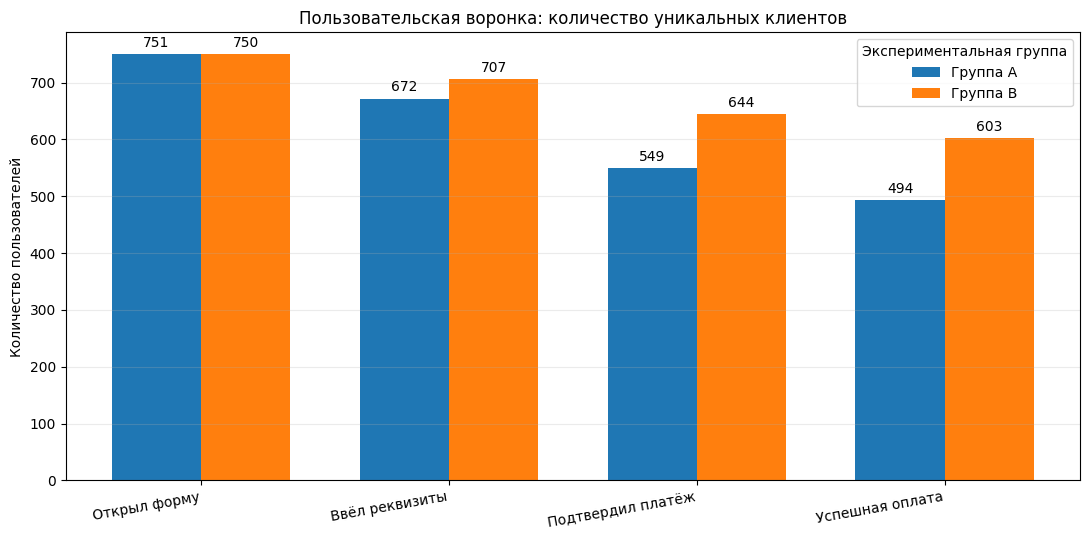

In [3]:
user_funnel_counts = users_ab.groupby('assigned_group')[stage_cols_user].sum().reindex(['A', 'B'])
user_funnel_counts = user_funnel_counts.rename(columns=user_stage_map)
user_funnel_counts.index.name = 'Группа'

display(user_funnel_counts.astype(int))

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(stage_labels))
width = 0.36
for i, group in enumerate(['A', 'B']):
    values = user_funnel_counts.loc[group].values
    positions = x + (i - 0.5) * width
    bars = ax.bar(positions, values, width=width, label=f'Группа {group}')
    ax.bar_label(bars, padding=3, fmt='%.0f')
ax.set_title('Пользовательская воронка: количество уникальных клиентов')
ax.set_ylabel('Количество пользователей')
ax.set_xticks(x, stage_labels, rotation=10, ha='right')
ax.legend(title='Экспериментальная группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Пользовательская конверсия от открытия формы

Основная метрика задания — доля уникальных пользователей с успешной оплатой среди уникальных пользователей, открывших форму.

,Открыл форму,Ввёл реквизиты,Подтвердил платёж,Успешная оплата
Группа,,,,
A,100.00%,89.48%,73.10%,65.78%
B,100.00%,94.27%,85.87%,80.40%


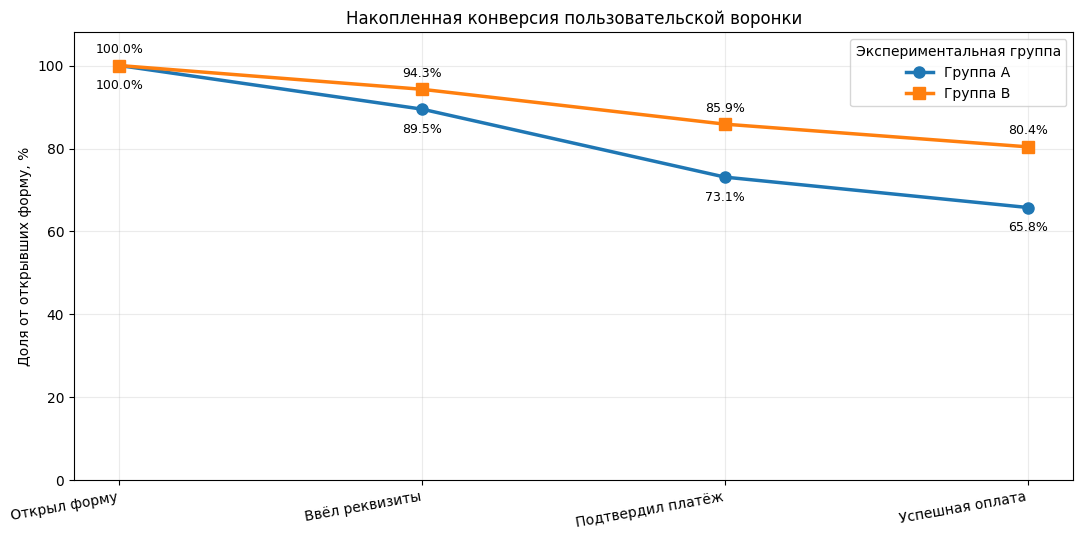

In [4]:
opened_denominator = users_ab.groupby('assigned_group')['opened_any'].sum().reindex(['A', 'B'])
user_funnel_rates = user_funnel_counts.div(opened_denominator, axis=0) * 100
user_funnel_rates.index.name = 'Группа'

display(user_funnel_rates.round(2).style.format('{:.2f}%'))

fig, ax = plt.subplots(figsize=(11, 5.5))
for group, marker in [('A', 'o'), ('B', 's')]:
    ax.plot(stage_labels, user_funnel_rates.loc[group].values, marker=marker,
            linewidth=2.5, markersize=8, label=f'Группа {group}')
    for x_pos, value in enumerate(user_funnel_rates.loc[group].values):
        ax.annotate(f'{value:.1f}%', (x_pos, value), textcoords='offset points',
                    xytext=(0, 9 if group == 'B' else -17), ha='center', fontsize=9)
ax.set_title('Накопленная конверсия пользовательской воронки')
ax.set_ylabel('Доля от открывших форму, %')
ax.set_ylim(0, 108)
ax.legend(title='Экспериментальная группа')
ax.grid(alpha=0.25)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

## 5. Конверсия между соседними этапами

Этот разрез помогает локализовать переход, на котором возникает наибольшее различие.

,Открытие → ввод,Ввод → подтверждение,Подтверждение → успех
Группа,,,
A,89.48%,81.70%,89.98%
B,94.27%,91.09%,93.63%


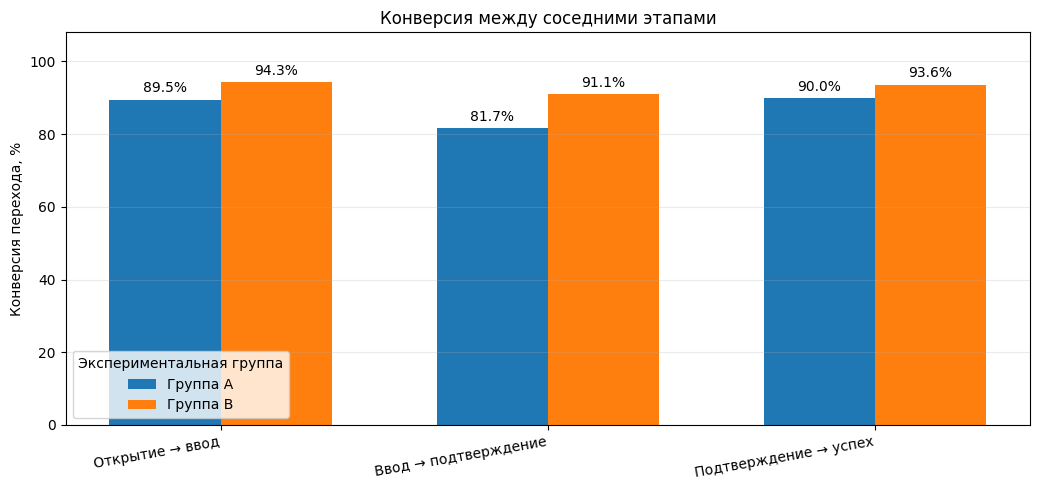

,"Разница B − A, п.п."
Открытие → ввод,4.790
Ввод → подтверждение,9.390
Подтверждение → успех,3.650


In [5]:
user_transition_rates = pd.DataFrame(index=['A', 'B'], columns=[
    'Открытие → ввод', 'Ввод → подтверждение', 'Подтверждение → успех'
], dtype=float)
user_transition_counts = {}

for group in ['A', 'B']:
    counts = user_funnel_counts.loc[group].astype(int).values
    rates = [counts[1] / counts[0], counts[2] / counts[1], counts[3] / counts[2]]
    user_transition_rates.loc[group] = np.array(rates) * 100
    user_transition_counts[group] = counts

user_transition_rates.index.name = 'Группа'
display(user_transition_rates.round(2).style.format('{:.2f}%'))

fig, ax = plt.subplots(figsize=(10.5, 5))
x = np.arange(user_transition_rates.shape[1])
width = 0.34
for i, group in enumerate(['A', 'B']):
    vals = user_transition_rates.loc[group].values
    bars = ax.bar(x + (i - 0.5) * width, vals, width=width, label=f'Группа {group}')
    ax.bar_label(bars, padding=3, fmt='%.1f%%')
ax.set_title('Конверсия между соседними этапами')
ax.set_ylabel('Конверсия перехода, %')
ax.set_xticks(x, user_transition_rates.columns, rotation=10, ha='right')
ax.set_ylim(0, 108)
ax.legend(title='Экспериментальная группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

transition_lift = (user_transition_rates.loc['B'] - user_transition_rates.loc['A']).rename('Разница B − A, п.п.')
display(transition_lift.to_frame().round(2))

## 6. Потери пользователей между этапами

Абсолютные потери показывают, сколько пользователей не перешло на следующий шаг. Дополнительно рассчитываем долю потерь от числа достигших предыдущего этапа.

group,A,B
transition,,
Открытие → ввод,79,43
Ввод → подтверждение,123,63
Подтверждение → успех,55,41


group,A,B
transition,,
Открытие → ввод,10.52%,5.73%
Ввод → подтверждение,18.30%,8.91%
Подтверждение → успех,10.02%,6.37%


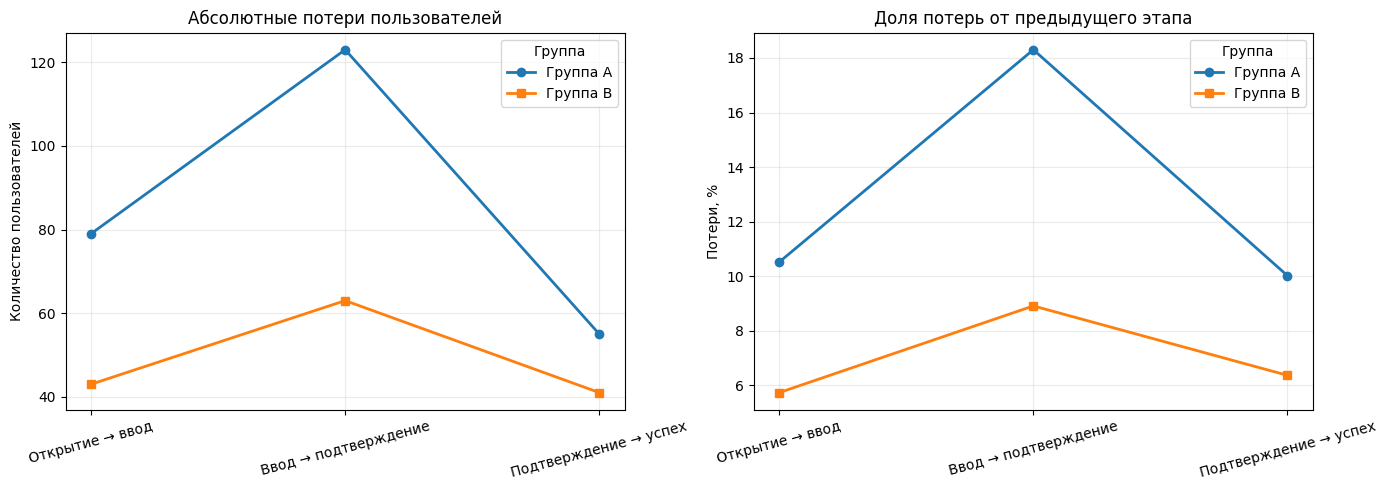

In [6]:
transition_names = ['Открытие → ввод', 'Ввод → подтверждение', 'Подтверждение → успех']
loss_records = []
for group in ['A', 'B']:
    counts = user_funnel_counts.loc[group].astype(int).values
    for i, transition in enumerate(transition_names):
        lost = counts[i] - counts[i + 1]
        loss_records.append({
            'group': group,
            'transition': transition,
            'users_lost': int(lost),
            'users_at_previous_step': int(counts[i]),
            'dropoff_rate_pct': lost / counts[i] * 100 if counts[i] else np.nan,
        })
loss_table = pd.DataFrame(loss_records)
display(loss_table.pivot(index='transition', columns='group', values='users_lost').reindex(transition_names))
display(loss_table.pivot(index='transition', columns='group', values='dropoff_rate_pct').reindex(transition_names).round(2).style.format('{:.2f}%'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for group, marker in [('A', 'o'), ('B', 's')]:
    subset = loss_table[loss_table['group'] == group].set_index('transition').reindex(transition_names)
    axes[0].plot(transition_names, subset['users_lost'], marker=marker, linewidth=2, label=f'Группа {group}')
    axes[1].plot(transition_names, subset['dropoff_rate_pct'], marker=marker, linewidth=2, label=f'Группа {group}')
axes[0].set_title('Абсолютные потери пользователей')
axes[0].set_ylabel('Количество пользователей')
axes[1].set_title('Доля потерь от предыдущего этапа')
axes[1].set_ylabel('Потери, %')
for ax in axes:
    ax.tick_params(axis='x', rotation=15)
    ax.grid(alpha=0.25)
    ax.legend(title='Группа')
plt.tight_layout()
plt.show()

## 7. Воронка отдельных попыток оплаты

Переключаем гранулярность: одна строка — одна попытка оплаты. Повторные попытки одного пользователя здесь учитываются отдельно.

,Открыл форму,Ввёл реквизиты,Подтвердил платёж,Успешная оплата
assigned_group,,,,
A,1309,1062,759,652
B,1351,1194,960,870


,Открыл форму,Ввёл реквизиты,Подтвердил платёж,Успешная оплата
assigned_group,,,,
A,100.00%,81.13%,57.98%,49.81%
B,100.00%,88.38%,71.06%,64.40%


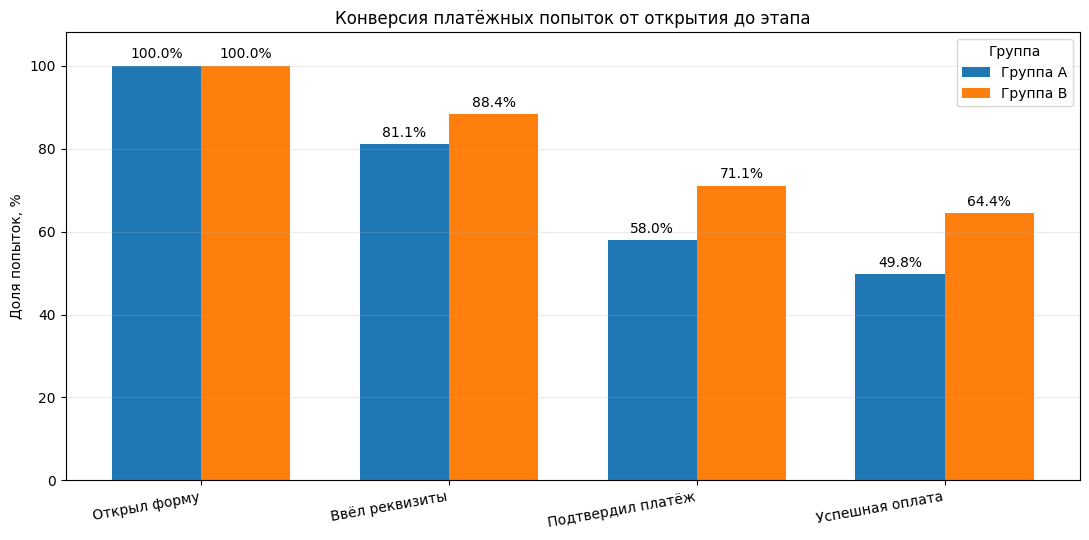

In [7]:
attempt_funnel_counts = attempts_ab.groupby('assigned_group')[stage_cols_attempt].sum().reindex(['A', 'B'])
attempt_funnel_counts = attempt_funnel_counts.rename(columns=attempt_stage_map)
attempt_funnel_rates = attempt_funnel_counts.div(
    attempts_ab.groupby('assigned_group')['opened'].sum().reindex(['A', 'B']), axis=0
) * 100

display(attempt_funnel_counts.astype(int))
display(attempt_funnel_rates.round(2).style.format('{:.2f}%'))

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(stage_labels))
width = 0.36
for i, group in enumerate(['A', 'B']):
    values = attempt_funnel_rates.loc[group].values
    bars = ax.bar(x + (i - 0.5) * width, values, width=width, label=f'Группа {group}')
    ax.bar_label(bars, padding=3, fmt='%.1f%%')
ax.set_title('Конверсия платёжных попыток от открытия до этапа')
ax.set_ylabel('Доля попыток, %')
ax.set_xticks(x, stage_labels, rotation=10, ha='right')
ax.set_ylim(0, 108)
ax.legend(title='Группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Время между этапами

Длительности рассчитываются внутри одной попытки оплаты, а не между первой попыткой пользователя и его последующим успехом. Это позволяет измерить время прохождения конкретного платежного сценария.

n  median   mean    p90    p95
transition            assigned_group                                   
Ввод → подтверждение  A                759   4.000  4.550  7.000  8.000
                      B                960   4.000  4.430  7.000  8.000
Открытие → ввод       A               1062   1.000  2.350  5.000  6.000
                      B               1194   1.000  2.430  5.000  6.000
Открытие → успех      A                652  12.000 12.410 16.000 17.000
                      B                870  12.000 12.350 16.000 17.000
Подтверждение → успех A                652   5.500  5.480  7.000  7.000
                      B                870   6.000  5.480  7.000  7.000

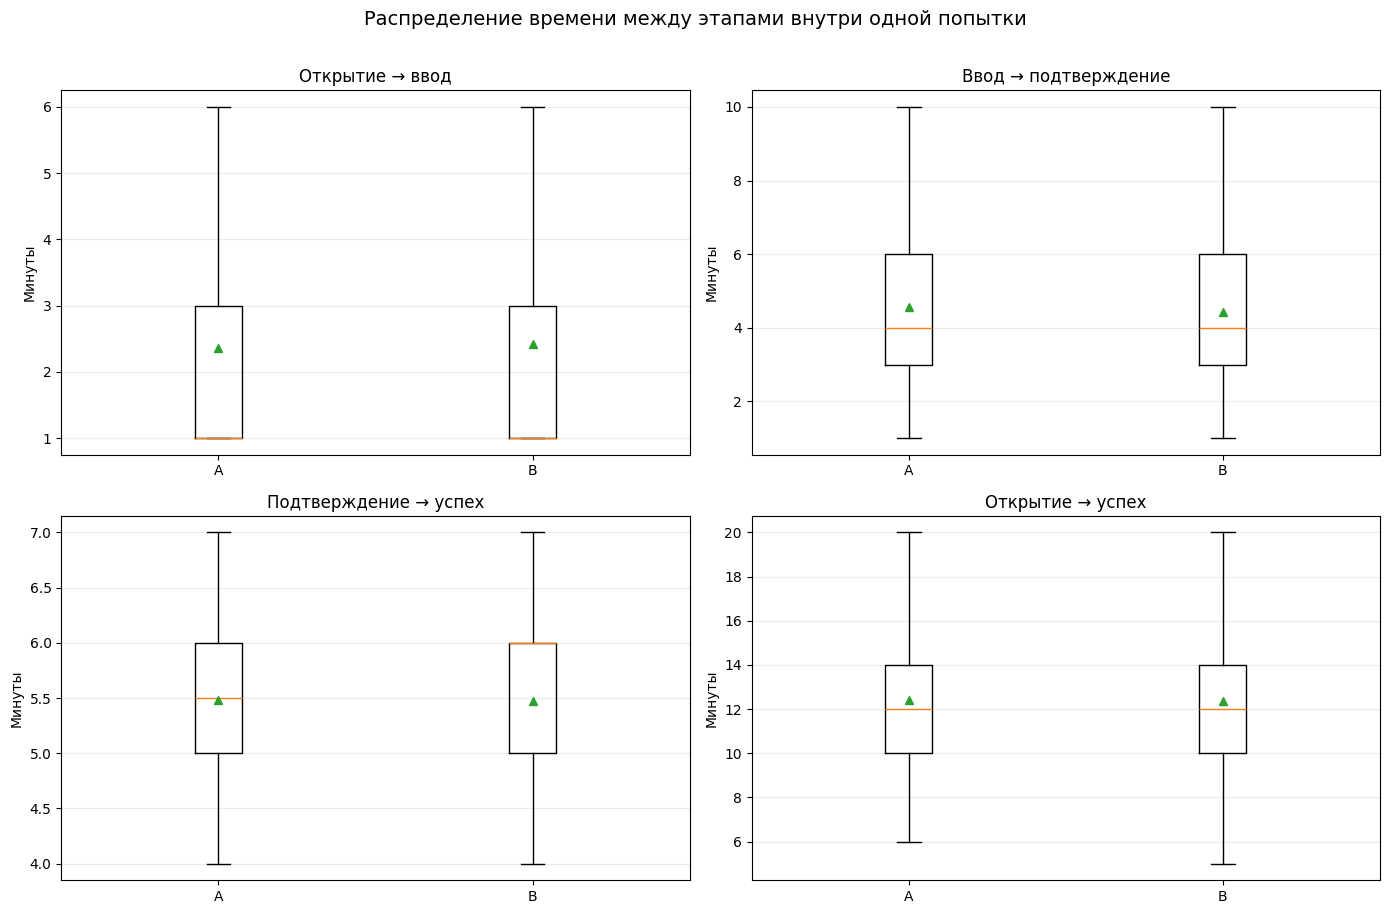

In [8]:
duration_specs = [
    ('minutes_open_to_enter', 'Открытие → ввод'),
    ('minutes_enter_to_confirm', 'Ввод → подтверждение'),
    ('minutes_confirm_to_success', 'Подтверждение → успех'),
    ('minutes_open_to_success', 'Открытие → успех'),
]
duration_frames = []
for col, label in duration_specs:
    temp = attempts_ab.loc[attempts_ab[col].notna(), ['assigned_group', 'payment_id', 'user_id', col]].copy()
    temp = temp.rename(columns={col: 'duration_minutes'})
    temp['transition'] = label
    duration_frames.append(temp)
duration_long = pd.concat(duration_frames, ignore_index=True)

duration_summary = (duration_long.groupby(['transition', 'assigned_group'])['duration_minutes']
                    .agg(n='count', median='median', mean='mean', p90=lambda x: x.quantile(0.90), p95=lambda x: x.quantile(0.95))
                    .round(2))
display(duration_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, label) in zip(axes.flat, duration_specs):
    data = [
        attempts_ab.loc[(attempts_ab['assigned_group'] == group) & attempts_ab[col].notna(), col].dropna().values
        for group in ['A', 'B']
    ]
    ax.boxplot(data, tick_labels=['A', 'B'], showfliers=False, showmeans=True)
    ax.set_title(label)
    ax.set_ylabel('Минуты')
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Распределение времени между этапами внутри одной попытки', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

## 9. Повторные попытки и успешная оплата

Смотрим, как распределено количество попыток на пользователя и какая доля клиентов с таким количеством попыток в итоге совершила успешную оплату хотя бы один раз.

,assigned_group,attempt_count,users,successful_users,eventual_success_rate
0,A,0,1,0,0.0%
1,A,1,387,196,50.6%
2,A,2,206,162,78.6%
3,A,3,122,102,83.6%
4,A,4,36,34,94.4%
5,B,0,1,0,0.0%
6,B,1,353,239,67.7%
7,B,2,237,210,88.6%
8,B,3,116,111,95.7%
9,B,4,44,43,97.7%


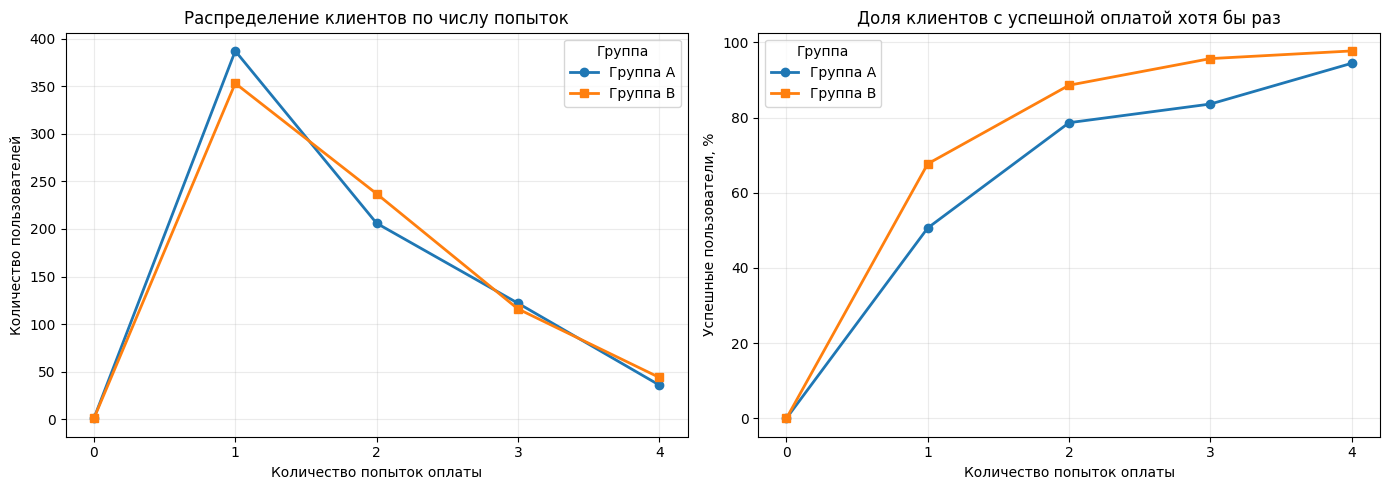

In [9]:
repeat_summary = (users_ab.groupby(['assigned_group', 'attempt_count'])
                 .agg(users=('user_id', 'nunique'), successful_users=('success_any', 'sum'))
                 .reset_index())
repeat_summary['eventual_success_rate'] = repeat_summary['successful_users'] / repeat_summary['users']
display(repeat_summary.style.format({'eventual_success_rate': '{:.1%}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for group, marker in [('A', 'o'), ('B', 's')]:
    subset = repeat_summary[repeat_summary['assigned_group'] == group]
    axes[0].plot(subset['attempt_count'], subset['users'], marker=marker, linewidth=2, label=f'Группа {group}')
    axes[1].plot(subset['attempt_count'], subset['eventual_success_rate'] * 100,
                 marker=marker, linewidth=2, label=f'Группа {group}')
axes[0].set_title('Распределение клиентов по числу попыток')
axes[0].set_ylabel('Количество пользователей')
axes[1].set_title('Доля клиентов с успешной оплатой хотя бы раз')
axes[1].set_ylabel('Успешные пользователи, %')
for ax in axes:
    ax.set_xlabel('Количество попыток оплаты')
    ax.set_xticks(sorted(users_ab['attempt_count'].unique()))
    ax.grid(alpha=0.25)
    ax.legend(title='Группа')
plt.tight_layout()
plt.show()

## 10. Сводная таблица продуктовых метрик


In [10]:
summary_records = []
for group in ['A', 'B']:
    g_users = users_ab[users_ab['assigned_group'] == group]
    g_attempts = attempts_ab[attempts_ab['assigned_group'] == group]
    assigned = g_users['user_id'].nunique()
    opened = int(g_users['opened_any'].sum())
    entered = int(g_users['entered_any'].sum())
    confirmed = int(g_users['confirmed_any'].sum())
    successful = int(g_users['success_any'].sum())
    summary_records.append({
        'group': group,
        'assigned_users': assigned,
        'opened_users': opened,
        'entered_users': entered,
        'confirmed_users': confirmed,
        'successful_users': successful,
        'open_to_success_cr': successful / opened,
        'itt_success_rate': successful / assigned,
        'payment_attempts': g_attempts['payment_id'].nunique(),
        'successful_attempts': int(g_attempts['success'].sum()),
        'attempt_success_rate': g_attempts['success'].mean(),
    })
product_summary = pd.DataFrame(summary_records).set_index('group')
display(product_summary.style.format({
    'open_to_success_cr': '{:.1%}',
    'itt_success_rate': '{:.1%}',
    'attempt_success_rate': '{:.1%}',
}))

cr_a = product_summary.loc['A', 'open_to_success_cr']
cr_b = product_summary.loc['B', 'open_to_success_cr']
print(f'Абсолютная разница пользовательской конверсии B − A: {(cr_b - cr_a) * 100:.2f} п.п.')
print(f'Относительный прирост конверсии B к A: {(cr_b / cr_a - 1) * 100:.2f}%')
print('Эти описательные оценки ещё не заменяют статистическую проверку.')

,assigned_users,opened_users,entered_users,confirmed_users,successful_users,open_to_success_cr,itt_success_rate,payment_attempts,successful_attempts,attempt_success_rate
group,,,,,,,,,,
A,752,751,672,549,494,65.8%,65.7%,1309,652,49.8%
B,751,750,707,644,603,80.4%,80.3%,1351,870,64.4%


Абсолютная разница пользовательской конверсии B − A: 14.62 п.п.
Относительный прирост конверсии B к A: 22.23%
Эти описательные оценки ещё не заменяют статистическую проверку.
